# 05. 텍스트 → 숫자 → 벡터 공간

모델은 숫자만 다룬다. 텍스트는 다음 순서로 바꾼다.

```
"the cat sat"  →  토큰화 ["the", "cat", "sat"]  →  ID [7, 2, 6]  →  nn.Embedding  →  벡터 (3, D)
```

임베딩 벡터는 학습되면서 **비슷한 의미의 단어가 가까이 모이는 공간**이 된다. 이것이 벡터 공간이다.

In [1]:
import re
import random
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt
from torch.utils.data import DataLoader, TensorDataset

torch.manual_seed(0)

## 1. 토큰화 — 글자 단위 / 단어 단위

In [2]:
text = "the cat sat on the mat. the dog sat on the log."

# 글자 단위
chars = sorted(set(text))
stoi = {c: i for i, c in enumerate(chars)}
itos = {i: c for c, i in stoi.items()}
encode = lambda s: [stoi[c] for c in s]
decode = lambda ids: "".join(itos[i] for i in ids)
print("글자 어휘:", len(chars), chars)
print(encode("the cat"), "→", decode(encode("the cat")))

글자 어휘: 14 [' ', '.', 'a', 'c', 'd', 'e', 'g', 'h', 'l', 'm', 'n', 'o', 's', 't']
[13, 7, 5, 0, 3, 2, 13] → the cat


In [3]:
# 단어 단위 + 특수 토큰
words = re.findall(r"\w+|[^\w\s]", text)
vocab = ["<pad>", "<unk>"] + sorted(set(words))
w2i = {w: i for i, w in enumerate(vocab)}
print("단어 어휘:", vocab)

def encode_words(s):
    return [w2i.get(w, w2i["<unk>"]) for w in re.findall(r"\w+|[^\w\s]", s)]

print(encode_words("the cat sat on the sofa ."))   # sofa는 어휘에 없음 → <unk>=1

단어 어휘: ['<pad>', '<unk>', '.', 'cat', 'dog', 'log', 'mat', 'on', 'sat', 'the']
[9, 3, 8, 7, 9, 1, 2]


| 방식 | 어휘 크기 | 시퀀스 길이 | 문제 |
| --- | --- | --- | --- |
| 글자 | 작음 | 김 | 의미 단위가 아님 |
| 단어 | 매우 큼 | 짧음 | 처음 보는 단어(OOV) → `<unk>` |
| 서브워드(BPE) | 중간 (GPT-2: 50,257) | 중간 | 자주 나오는 조각을 합쳐 만든 절충안. GPT 계열이 사용 |

In [4]:
try:
    import tiktoken
    enc = tiktoken.get_encoding("gpt2")      # 첫 실행 시 BPE 파일 다운로드
    ids = enc.encode("unbelievably tokenization")
    print(ids, [enc.decode([i]) for i in ids])
except Exception as e:
    print("tiktoken 사용 불가 (오프라인?):", e)

[403, 6667, 11203, 1346, 11241, 1634] ['un', 'bel', 'iev', 'ably', ' token', 'ization']


## 2. One-hot vs `nn.Embedding`

- One-hot: 어휘 크기만큼의 차원에 1이 하나. 모든 단어가 서로 직교하므로 **유사도 정보가 없다**.
- Embedding: `D`차원의 실수 벡터이고 **학습된다**. 내부적으로는 `(V, D)` 가중치 행렬에서 행을 꺼내는 것으로, `one_hot @ W`와 같다.

In [5]:
V, D = len(vocab), 4
emb = nn.Embedding(V, D)
ids = torch.tensor([w2i["cat"], w2i["dog"]])

print("emb.weight:", emb.weight.shape)          # (V, D)
print(emb(ids))                                  # (2, D)

one_hot = F.one_hot(ids, num_classes=V).float()  # (2, V)
print("one_hot @ W == emb(ids):", torch.allclose(one_hot @ emb.weight, emb(ids)))

emb.weight: torch.Size([10, 4])
tensor([[ 0.1198,  1.2377,  1.1168, -0.2473],
        [-1.3527, -1.6959,  0.5667,  0.7935]], grad_fn=<EmbeddingBackward0>)
one_hot @ W == emb(ids): True


## 3. 코사인 유사도

$$\cos\theta = \frac{a \cdot b}{\|a\|\,\|b\|}$$

1이면 같은 방향, 0이면 무관(직교), -1이면 반대 방향이다. 벡터의 길이는 무시하고 방향만 본다.

In [6]:
def cosine(a, b):
    return (a @ b) / (a.norm() * b.norm())

a = torch.tensor([1., 2., 3.])
print(cosine(a, a * 10).item())                          # 1.0 (길이 무관)
print(cosine(a, torch.tensor([-3., 0., 1.])).item())     # 0.0 (직교)
print(F.cosine_similarity(a, -a, dim=0).item())          # -1.0

1.0
0.0
-0.9999998807907104


## 4. Word2Vec (Skip-gram) 직접 학습하기

**분포 가설**: 비슷한 문맥에 나오는 단어는 의미도 비슷하다.

Skip-gram은 **가운데 단어로 주변 단어를 맞추는** 문제를 푼다.
`Embedding(V, D) → Linear(D, V) → CrossEntropy` 구조이고, 학습이 끝난 뒤 **Embedding 가중치의 각 행이 단어 벡터**가 된다.

정답을 알 수 있도록, 4개 그룹(왕족/동물/음식/탈것)이 각자 정해진 문맥에만 등장하는 인공 말뭉치를 만든다.

In [7]:
random.seed(0)
groups = {
    "royal":   ["king", "queen", "prince", "princess"],
    "animal":  ["dog", "cat", "puppy", "kitten"],
    "food":    ["apple", "bread", "rice", "banana"],
    "vehicle": ["car", "bus", "truck", "train"],
}
templates = {
    "royal":   ["the {} rules the kingdom", "the {} wears a golden crown", "the {} lives in the castle"],
    "animal":  ["the {} chases the ball", "the {} sleeps on the rug", "the {} plays in the yard"],
    "food":    ["i eat the {} for lunch", "the {} tastes sweet and fresh", "she cooks the {} in the kitchen"],
    "vehicle": ["the {} drives on the road", "he parks the {} in the garage", "the {} needs more fuel"],
}
sentences = []
for _ in range(2000):
    g = random.choice(list(groups))
    sentences.append(random.choice(templates[g]).format(random.choice(groups[g])))
print(sentences[:5])

['he parks the car in the garage', 'she cooks the banana in the kitchen', 'he parks the train in the garage', 'she cooks the bread in the kitchen', 'the cat sleeps on the rug']


In [8]:
tokens = [s.split() for s in sentences]
vocab = sorted({w for sent in tokens for w in sent})
w2i = {w: i for i, w in enumerate(vocab)}

# (가운데 단어, 주변 단어) 쌍 만들기, window=2
pairs = []
for sent in tokens:
    ids = [w2i[w] for w in sent]
    for i, center in enumerate(ids):
        for j in range(max(0, i - 2), min(len(ids), i + 3)):
            if j != i:
                pairs.append((center, ids[j]))
pairs = torch.tensor(pairs)
print("어휘 수:", len(vocab), "| 학습 쌍:", pairs.shape)
print("예:", [(vocab[c], vocab[o]) for c, o in pairs[:6].tolist()])

어휘 수: 52 | 학습 쌍: torch.Size([35408, 2])
예: [('he', 'parks'), ('he', 'the'), ('parks', 'he'), ('parks', 'the'), ('parks', 'car'), ('the', 'he')]


In [9]:
class SkipGram(nn.Module):
    def __init__(self, vocab_size, emb_dim):
        super().__init__()
        self.emb = nn.Embedding(vocab_size, emb_dim)
        self.out = nn.Linear(emb_dim, vocab_size)

    def forward(self, center):              # (B,)
        return self.out(self.emb(center))   # (B, V) : 주변 단어에 대한 logits


torch.manual_seed(0)
model = SkipGram(len(vocab), emb_dim=16)
optimizer = torch.optim.Adam(model.parameters(), lr=0.01)
loader = DataLoader(TensorDataset(pairs[:, 0], pairs[:, 1]), batch_size=256, shuffle=True)

for epoch in range(5):
    total = 0.0
    for center, context in loader:
        optimizer.zero_grad()
        loss = F.cross_entropy(model(center), context)
        loss.backward()
        optimizer.step()
        total += loss.item()
    print(f"epoch {epoch}  loss {total / len(loader):.3f}")

epoch 0  loss 2.781


epoch 1  loss 2.182


epoch 2  loss 2.129


epoch 3  loss 2.115


epoch 4  loss 2.112


In [10]:
W = model.emb.weight.detach()            # (V, D) : 학습된 단어 벡터
Wn = F.normalize(W, dim=1)               # 길이 1로 정규화 → 내적 = 코사인 유사도
sim = Wn @ Wn.T                          # (V, V)

def nearest(word, k=4):
    s = sim[w2i[word]].clone()
    s[w2i[word]] = -1                    # 자기 자신 제외
    top = s.topk(k)
    return [(vocab[i], round(v, 2)) for v, i in zip(top.values.tolist(), top.indices.tolist())]

for w in ["king", "dog", "apple", "car"]:
    print(f"{w:6s} →", nearest(w))

king   → [('princess', 0.74), ('queen', 0.59), ('prince', 0.59), ('i', 0.51)]
dog    → [('kitten', 0.88), ('puppy', 0.79), ('cat', 0.79), ('train', 0.47)]
apple  → [('rice', 0.84), ('bread', 0.78), ('banana', 0.75), ('castle', 0.51)]
car    → [('truck', 0.91), ('bus', 0.68), ('train', 0.64), ('road', 0.54)]


같은 그룹 단어끼리 가장 가깝게 나오면 성공이다. 16차원을 2차원으로 줄여(PCA) 그려 보면 그룹별로 모여 있다.

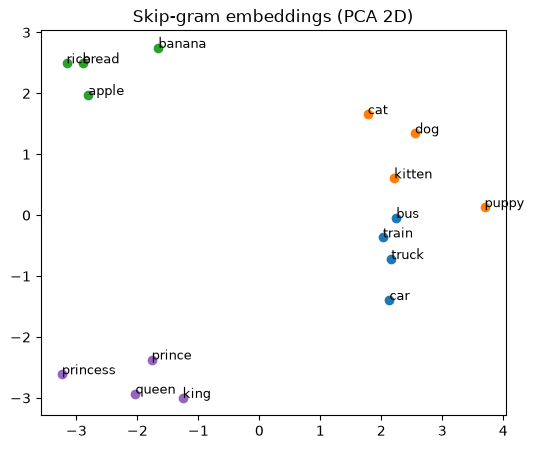

In [11]:
targets = [w for g in groups.values() for w in g]
E = W[[w2i[w] for w in targets]]
E = E - E.mean(dim=0)
U, S, Vt = torch.linalg.svd(E, full_matrices=False)
xy = E @ Vt[:2].T                         # 주성분 2개로 투영

colors = {"royal": "tab:purple", "animal": "tab:orange", "food": "tab:green", "vehicle": "tab:blue"}
plt.figure(figsize=(6, 5))
for g, ws in groups.items():
    for w in ws:
        i = targets.index(w)
        plt.scatter(xy[i, 0], xy[i, 1], color=colors[g])
        plt.annotate(w, (xy[i, 0], xy[i, 1]), fontsize=9)
plt.title("Skip-gram embeddings (PCA 2D)")
plt.show()

## 5. (참고) 사전학습 단어 벡터 — 교안 Chapter 1

실제로는 거대한 말뭉치로 미리 학습된 벡터(GloVe, Word2Vec)를 가져다 쓴다.
아래 코드를 `True`로 바꾸면 약 65MB를 내려받는다.

In [12]:
RUN_GLOVE = False
if RUN_GLOVE:
    import gensim.downloader as api
    glove = api.load("glove-wiki-gigaword-50")
    print(glove.similarity("cat", "dog"), glove.similarity("cat", "car"))
    print(glove.most_similar(positive=["king", "woman"], negative=["man"], topn=3))   # king - man + woman